<table>
    <tr>
        <td colspan=2><strong>International University of La Rioja (UNIR)</strong></td>
    </tr>
    <tr>
        <td colspan=2><strong>Master's Degree in Mathematical Engineering and Computing</strong></td>
    </tr>
    <tr>
        <td>Master's thesis submitted by:</td>
        <td><strong>Andrés Benavides, Diego Salamanca, Yeferson Salamanca.</strong></td>
    </tr>
    <tr>
        <td>Supervisor:</td>
        <td>PhD. Juan Francisco Martínez Cerda</td>
    </tr>
</table>


---


# 03 - Visualize processed stock and macro data

This notebook is a **visual sanity check** of the clean dataset produced by `02_merge_data.ipynb`. It reads the processed CSV, verifies that the sector and macro columns configured in `metadata/tickers.json` are present, and plots the series so any missing values, scaling issues, or obvious data anomalies are easy to spot before modeling. It is read-only: it produces inline figures and does not write any files.

**Inputs**
- `data/processed/merged_processed_data.csv` - the numeric, weekday-only, imputed dataset from notebook 02.1.
- `metadata/tickers.json` - sector / macro ticker lists and the columns to keep per group (`sectors_columns_to_keep`, `macro_columns_to_keep`).

**Outputs**
- Inline only: stock price charts by sector and macro index charts. Nothing is saved to disk.

**Sections**
1. Imports and paths.
2. Load metadata and processed data.
3. Check that the configured tickers and columns are present in the CSV.
4. Stock price charts grouped by sector (using sector tickers and `sectors_columns_to_keep`).
5. Macro index charts (using macro tickers and `macro_columns_to_keep`).

## 1. Imports and paths

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    display = print

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
METADATA_PATH = PROJECT_ROOT / "metadata" / "tickers.json"
PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "merged_processed_data.csv"

print(f"PROJECT_ROOT   : {PROJECT_ROOT}")
print(f"METADATA_PATH  : {METADATA_PATH}")
print(f"PROCESSED_PATH : {PROCESSED_PATH}")

Matplotlib is building the font cache; this may take a moment.


PROJECT_ROOT   : /Applications/TFM_LSTM
METADATA_PATH  : /Applications/TFM_LSTM/metadata/tickers.json
PROCESSED_PATH : /Applications/TFM_LSTM/data/processed/merged_processed_data.csv


## 2. Load metadata and processed data

In [2]:
with METADATA_PATH.open("r", encoding="utf-8") as f:
    metadata = json.load(f)

sectors = metadata["sectors"]
macro = metadata["macro"]
sectors_columns_to_keep = metadata.get("sectors_columns_to_keep", [])
macro_columns_to_keep = metadata.get("macro_columns_to_keep", [])

df = (
    pd.read_csv(PROCESSED_PATH, parse_dates=["Date"])
    .sort_values("Date")
    .set_index("Date")
)

print(f"Rows          : {len(df):,}")
print(f"Columns       : {len(df.columns):,}")
print(f"Date range    : {df.index.min().date()} to {df.index.max().date()}")
print(f"Sector fields : {sectors_columns_to_keep}")
print(f"Macro fields  : {macro_columns_to_keep}")

df.head()

Rows          : 3,018
Columns       : 53
Date range    : 2014-05-30 to 2026-05-29
Sector fields : ['Adj Close', 'Volume']
Macro fields  : ['Adj Close']


,AAPL_Adj Close,AAPL_Volume,MSFT_Adj Close,MSFT_Volume,NVDA_Adj Close,NVDA_Volume,GOOGL_Adj Close,GOOGL_Volume,AMZN_Adj Close,AMZN_Volume,LLY_Adj Close,LLY_Volume,UNH_Adj Close,UNH_Volume,JNJ_Adj Close,JNJ_Volume,MRK_Adj Close,MRK_Volume,ISRG_Adj Close,ISRG_Volume,DE_Adj Close,DE_Volume,ADM_Adj Close,ADM_Volume,BG_Adj Close,...,CF_Adj Close,CF_Volume,XOM_Adj Close,XOM_Volume,CVX_Adj Close,CVX_Volume,COP_Adj Close,COP_Volume,EOG_Adj Close,EOG_Volume,SLB_Adj Close,SLB_Volume,JPM_Adj Close,JPM_Volume,BLK_Adj Close,BLK_Volume,GS_Adj Close,GS_Volume,MS_Adj Close,MS_Volume,AXP_Adj Close,AXP_Volume,^VIX_Adj Close,DX-Y.NYB_Adj Close,^TNX_Adj Close
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2014-05-30,19.825077,564020800.0,34.310696,34567600.0,0.451953,239128000.0,28.348204,37434000.0,15.627500,85204000.0,48.201237,4803000.0,65.400620,5139900.0,72.911400,5973900.0,38.076218,12071912.0,41.082222,2744100.0,73.251915,1768400.0,31.780403,2011300.0,55.651802,...,35.076782,4403000.0,61.016968,11499000.0,73.828804,5174700.0,54.168633,5991400.0,75.831909,2293300.0,75.026306,4666500.0,40.331413,11991900.0,226.546371,365100.0,127.069298,2206300.0,22.510998,7634400.0,77.304619,3594800.0,11.40,80.370003,2.457
2014-06-02,19.688843,369350800.0,34.184971,18504300.0,0.450525,181500000.0,27.985695,33210000.0,15.442000,44068000.0,47.903309,3405700.0,65.269218,1986400.0,73.421616,5845400.0,38.122295,6733924.0,41.211109,3545100.0,73.259972,1941100.0,31.716757,2295300.0,55.150520,...,35.248337,3580000.0,60.658855,7761300.0,73.480064,3689800.0,53.856911,5071900.0,75.530876,1712400.0,75.221764,3748000.0,40.171722,9440000.0,227.385971,404200.0,127.244278,2162500.0,22.540169,7509400.0,77.634140,2832100.0,11.58,80.639999,2.534
2014-06-03,19.967274,292709200.0,33.765945,18068900.0,0.448622,243212000.0,27.498230,40626000.0,15.359500,47584000.0,47.790569,2798200.0,65.605957,2841100.0,73.630005,6681300.0,38.109135,7417849.0,41.215557,2184300.0,72.986801,1589600.0,31.363174,2483000.0,54.914196,...,35.239693,3298500.0,60.931973,9384200.0,73.684502,3563800.0,54.087296,4551700.0,76.448296,1974800.0,75.178307,3503900.0,40.353172,9131500.0,229.302963,719300.0,128.651566,2408600.0,22.503696,10079500.0,77.498924,2589100.0,11.87,80.550003,2.593
2014-06-04,20.195278,335482000.0,33.791069,23209000.0,0.449098,161236000.0,27.461033,34582000.0,15.339000,42142000.0,47.685894,2997400.0,66.123390,3552900.0,73.788094,5608600.0,38.122295,7205419.0,41.125557,2690100.0,72.986801,1431000.0,31.334894,2287700.0,53.976028,...,35.310333,4229000.0,60.719551,7148800.0,73.564240,3285500.0,54.073746,3585400.0,76.240417,1695600.0,75.084236,4815100.0,40.411247,9727800.0,230.892960,558200.0,129.120773,2098400.0,22.759003,8074700.0,77.566490,2637000.0,12.08,80.669998,2.606
2014-06-05,20.274511,303805600.0,34.536945,31865200.0,0.451001,188696000.0,28.014956,35868000.0,16.178499,155934000.0,47.975773,2753800.0,65.540245,3453700.0,74.176155,4730900.0,38.234165,8007349.0,40.982224,3270600.0,73.356415,1888900.0,31.801605,2506400.0,54.513145,...,35.303116,2516000.0,61.029114,12296100.0,74.267738,4220600.0,54.243145,4144600.0,77.337074,2212100.0,75.221764,4055600.0,41.100739,16803400.0,231.722946,566400.0,129.271790,1859600.0,23.072668,8769400.0,78.402916,3219200.0,11.68,80.370003,2.584


## 3. Check configured tickers and columns

In [3]:
def build_column_check(ticker_groups, columns_to_keep, group_name):
    rows = []
    for group, tickers in ticker_groups.items():
        for ticker, label in tickers.items():
            for field in columns_to_keep:
                csv_column = f"{ticker}_{field}"
                rows.append(
                    {
                        group_name: group,
                        "ticker": ticker,
                        "label": label,
                        "metadata_field": field,
                        "csv_column": csv_column,
                        "present_in_processed_data": csv_column in df.columns,
                    }
                )
    return pd.DataFrame(rows)

sector_check = build_column_check(sectors, sectors_columns_to_keep, "sector")
macro_check = build_column_check({"macro": macro}, macro_columns_to_keep, "group")

summary = pd.DataFrame(
    [
        {
            "group": "sector",
            "tickers": sum(len(tickers) for tickers in sectors.values()),
            "metadata_fields": ", ".join(sectors_columns_to_keep),
            "expected_columns": len(sector_check),
            "missing_columns": int((~sector_check["present_in_processed_data"]).sum()),
        },
        {
            "group": "macro",
            "tickers": len(macro),
            "metadata_fields": ", ".join(macro_columns_to_keep),
            "expected_columns": len(macro_check),
            "missing_columns": int((~macro_check["present_in_processed_data"]).sum()),
        },
    ]
)

display(summary)
display(sector_check)
display(macro_check)

missing_columns = pd.concat(
    [
        sector_check.loc[~sector_check["present_in_processed_data"], ["csv_column"]],
        macro_check.loc[~macro_check["present_in_processed_data"], ["csv_column"]],
    ],
    ignore_index=True,
)["csv_column"].tolist()

if missing_columns:
    raise ValueError(f"Missing expected processed-data columns: {missing_columns}")

,group,tickers,metadata_fields,expected_columns,missing_columns
0,sector,25,"Adj Close, Volume",50,0
1,macro,3,Adj Close,3,0


,sector,ticker,label,metadata_field,csv_column,present_in_processed_data
0,technology,AAPL,Apple Inc.,Adj Close,AAPL_Adj Close,True
1,technology,AAPL,Apple Inc.,Volume,AAPL_Volume,True
2,technology,MSFT,Microsoft Corporation,Adj Close,MSFT_Adj Close,True
3,technology,MSFT,Microsoft Corporation,Volume,MSFT_Volume,True
4,technology,NVDA,NVIDIA Corporation,Adj Close,NVDA_Adj Close,True
5,technology,NVDA,NVIDIA Corporation,Volume,NVDA_Volume,True
6,technology,GOOGL,Alphabet Inc.,Adj Close,GOOGL_Adj Close,True
7,technology,GOOGL,Alphabet Inc.,Volume,GOOGL_Volume,True
8,technology,AMZN,"Amazon.com, Inc.",Adj Close,AMZN_Adj Close,True
9,technology,AMZN,"Amazon.com, Inc.",Volume,AMZN_Volume,True


,group,ticker,label,metadata_field,csv_column,present_in_processed_data
0,macro,^VIX,CBOE Volatility Index,Adj Close,^VIX_Adj Close,True
1,macro,DX-Y.NYB,U.S. Dollar Index (DXY),Adj Close,DX-Y.NYB_Adj Close,True
2,macro,^TNX,CBOE 10-Year Treasury Note Yield Index,Adj Close,^TNX_Adj Close,True


## 4. Stock price charts by sector

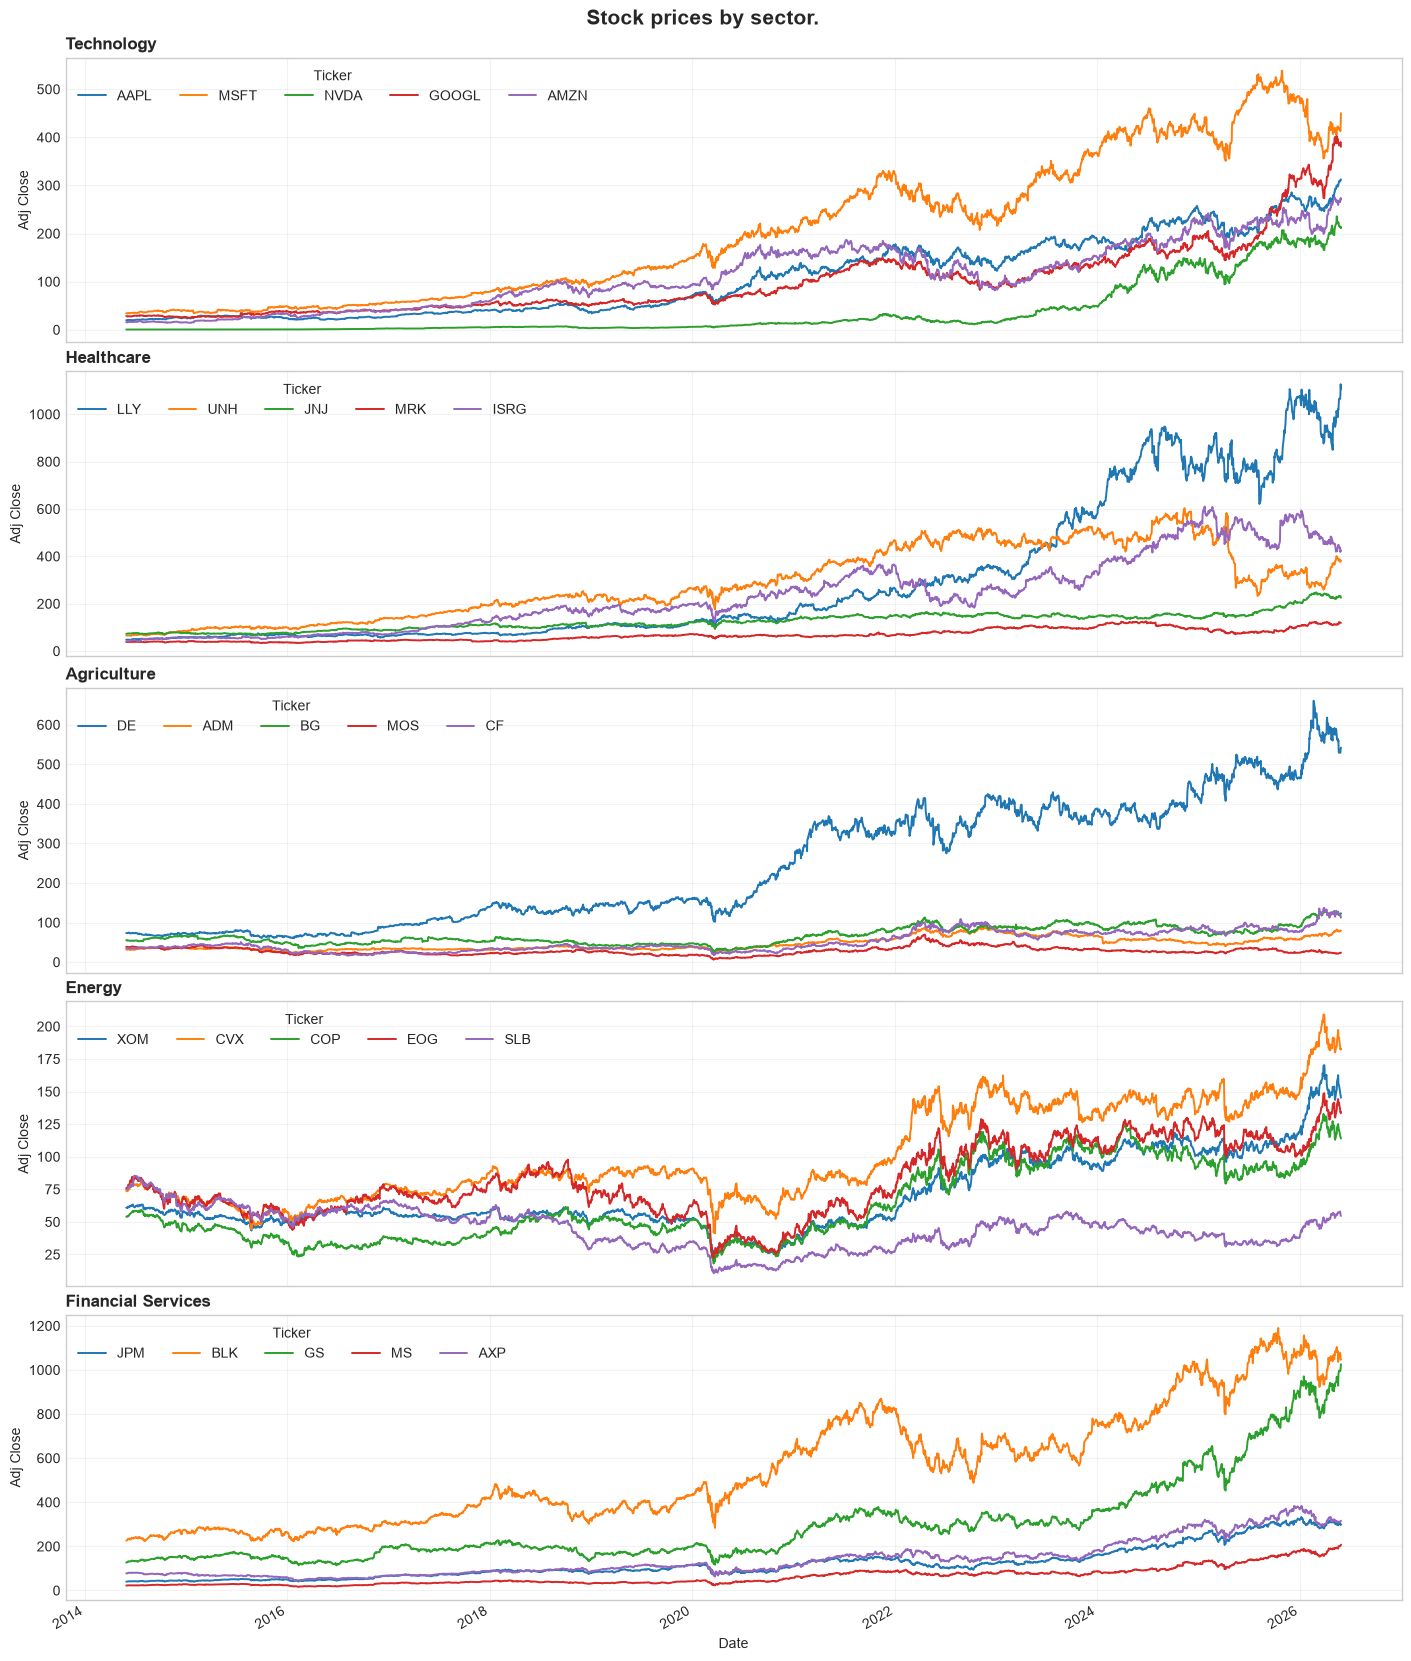

In [5]:
PRICE_COLUMN = "Adj Close"
NORMALIZE_TO_100 = False

if PRICE_COLUMN not in sectors_columns_to_keep:
    raise ValueError(
        f"{PRICE_COLUMN!r} is not listed in metadata['sectors_columns_to_keep']: "
        f"{sectors_columns_to_keep}"
    )


def normalize_to_100(plot_data):
    first_valid = plot_data.apply(lambda col: col.dropna().iloc[0] if not col.dropna().empty else pd.NA)
    return plot_data.divide(first_valid).multiply(100)


def plot_sector_prices(title,data, sector_map, price_column, normalize=False):
    fig, axes = plt.subplots(
        nrows=len(sector_map),
        ncols=1,
        figsize=(14, 3.3 * len(sector_map)),
        sharex=True,
        constrained_layout=True,
    )

    if len(sector_map) == 1:
        axes = [axes]

    for ax, (sector_name, tickers) in zip(axes, sector_map.items()):
        columns = [f"{ticker}_{price_column}" for ticker in tickers if f"{ticker}_{price_column}" in data.columns]
        labels = {f"{ticker}_{price_column}": ticker for ticker in tickers}
        plot_data = data[columns].rename(columns=labels).dropna(how="all")

        if normalize:
            plot_data = normalize_to_100(plot_data)

        plot_data.plot(ax=ax, linewidth=1.4)
        ax.set_title(sector_name.replace("_", " ").title(), loc="left", fontsize=12, fontweight="bold")
        ax.set_ylabel(f"{price_column}{' (index=100)' if normalize else ''}")
        ax.legend(title="Ticker", ncols=min(5, max(1, len(plot_data.columns))))
        ax.grid(True, alpha=0.25)

    axes[-1].set_xlabel("Date")
    fig.suptitle(
        f"{title}. {'normalized to 100' if normalize else ''}",
        fontsize=15,
        fontweight="bold",
    )
    plt.show()


plot_sector_prices("Stock prices by sector",df, sectors, PRICE_COLUMN, normalize=NORMALIZE_TO_100)

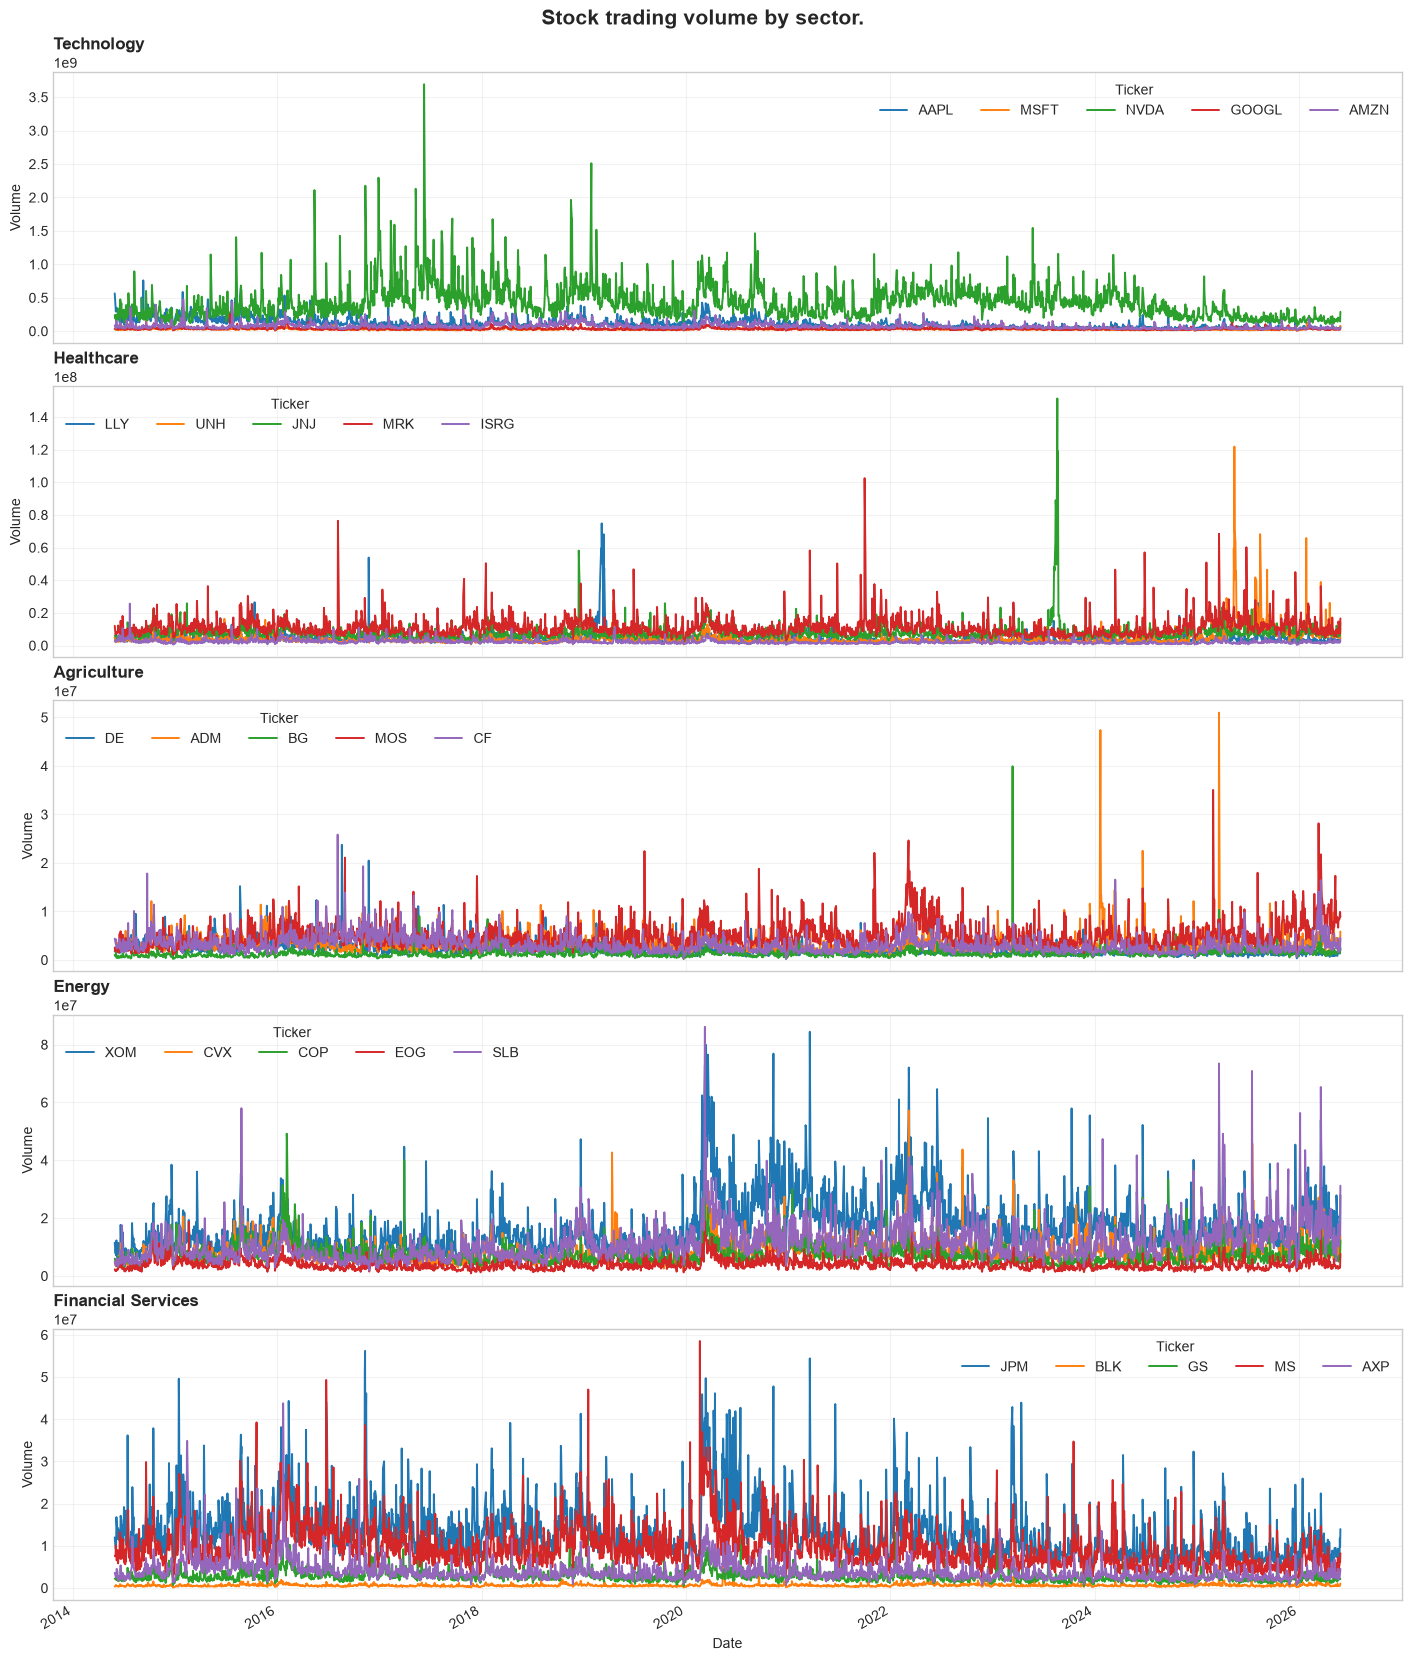

In [5]:
plot_sector_prices("Stock trading volume by sector", df, sectors, price_column="Volume", normalize=NORMALIZE_TO_100)

## 5. Macro index charts

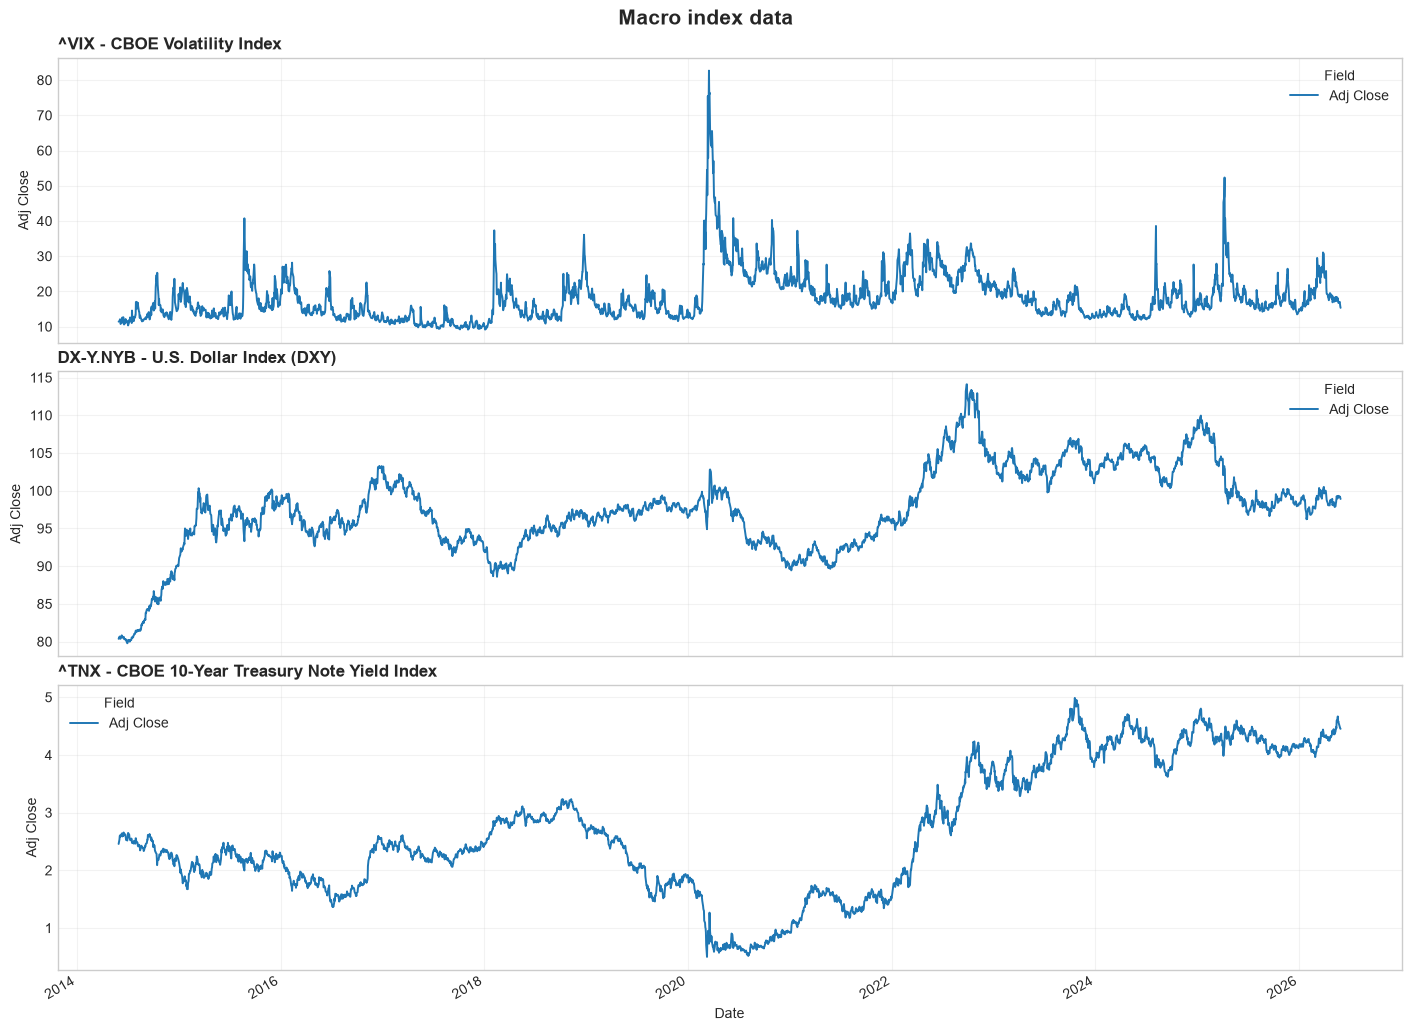

In [6]:
def plot_macro_data(data, macro_map, columns_to_keep):
    fig, axes = plt.subplots(
        nrows=len(macro_map),
        ncols=1,
        figsize=(14, 3.4 * len(macro_map)),
        sharex=True,
        constrained_layout=True,
    )

    if len(macro_map) == 1:
        axes = [axes]

    for ax, (ticker, label) in zip(axes, macro_map.items()):
        columns = [f"{ticker}_{field}" for field in columns_to_keep if f"{ticker}_{field}" in data.columns]
        labels = {f"{ticker}_{field}": field for field in columns_to_keep}
        plot_data = data[columns].rename(columns=labels).dropna(how="all")

        plot_data.plot(ax=ax, linewidth=1.4)
        ax.set_title(f"{ticker} - {label}", loc="left", fontsize=12, fontweight="bold")
        ax.set_ylabel(", ".join(columns_to_keep))
        ax.legend(title="Field")
        ax.grid(True, alpha=0.25)

    axes[-1].set_xlabel("Date")
    fig.suptitle("Macro index data", fontsize=15, fontweight="bold")
    plt.show()


plot_macro_data(df, macro, macro_columns_to_keep)